In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 3 — Challenge A: multinomial logistic regression (cyber)

**Team:** Team 1 · **Milestone:** P3

**Roles:** R1 Marina García, R2 Diana Luque, R3 Francisco Moya, R4 Claudia Martínez, R5 Fernando Caceres

Primary metric: **macro F1**, on the canonical `cyber_folds.csv` assignment.

# Data and preprocessing (R1)

## Setup

In [2]:
import json
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# These paths start from the notebooks folder, where this file is run.
CYBER_DIR = "../datos/cyber"
FOLDS_DIR = "../folds"

## Data

In [3]:
# We load the data and the auxiliary files without modifying the originals.
dev = pd.read_csv(CYBER_DIR + "/cyber_development.csv")
cyber_groups = pd.read_csv(CYBER_DIR + "/cyber_groups.csv")
cyber_folds = pd.read_csv(FOLDS_DIR + "/cyber_folds.csv")

# The JSON keys are text; we convert them to the integer codes of y.
with open(CYBER_DIR + "/cyber_class_codes.json", encoding="utf-8") as file:
    class_codes = json.load(file)

CLASS_NAMES = {}
for code, name in class_codes.items():
    CLASS_NAMES[int(code)] = name

print("Development table:", dev.shape)
print("Class names:", CLASS_NAMES)

Development table: (34928, 13)
Class names: {0: 'backdoor', 1: 'ddos', 2: 'dos', 3: 'injection', 4: 'mitm', 5: 'normal', 6: 'password', 7: 'ransomware', 8: 'scanning', 9: 'xss'}


In [4]:
# We keep the 11 predictors of P2 and separate the target.
NOMINAL = ["proto", "service", "conn_state"]
NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes",
           "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]
FEATURES = NOMINAL + NUMERIC

expected_columns = ["row_id"] + FEATURES + ["attack_code"]
assert list(dev.columns) == expected_columns, "Unexpected cyber schema"

# We select the columns explicitly: the metadata never enter X.
X = dev[FEATURES].copy()
y = dev["attack_code"].copy()
for column in ["row_id", "feature_group", "config_group", "fold_id", "attack_code"]:
    assert column not in X.columns, "Forbidden predictor: " + column

assert X.shape[1] == 11, "Expected 11 source predictors"
assert not dev.isna().any().any(), "Missing values in development data"
assert np.isfinite(X[NUMERIC].to_numpy()).all(), "Non-finite numeric predictors"
assert (X[NUMERIC] >= 0).all().all(), "Negative values are incompatible with log1p"
assert pd.api.types.is_integer_dtype(y), "Class codes must be integers"
assert sorted(y.unique()) == sorted(CLASS_NAMES), "Class codes do not match JSON"

print("Predictors:", X.shape)
print("Target:", y.name)
print("Schema, predictor and target checks passed.")

Predictors: (34928, 11)
Target: attack_code
Schema, predictor and target checks passed.


In [5]:
# Before using positions, we check that the three files are aligned.
assert list(cyber_groups.columns) == ["row_id", "feature_group"], "Unexpected group schema"
assert list(cyber_folds.columns) == ["row_id", "fold_id"], "Unexpected fold schema"
assert dev["row_id"].is_unique, "Duplicate development row_id"
assert cyber_groups["row_id"].is_unique, "Duplicate group row_id"
assert cyber_folds["row_id"].is_unique, "Duplicate fold row_id"
assert not cyber_groups.isna().any().any(), "Missing group metadata"
assert not cyber_folds.isna().any().any(), "Missing fold metadata"
assert dev["row_id"].equals(cyber_groups["row_id"]), "Group rows are not aligned"
assert dev["row_id"].equals(cyber_folds["row_id"]), "Fold rows are not aligned"
assert sorted(cyber_folds["fold_id"].unique()) == [0, 1, 2, 3, 4], "Expected five folds"

print("Row identifiers are unique and aligned across all three tables.")
print("Feature groups:", cyber_groups["feature_group"].nunique())

Row identifiers are unique and aligned across all three tables.
Feature groups: 34883


In [6]:
# We read the official assignment: we neither generate nor change the partitions.
# np.flatnonzero returns the positions that satisfy each condition.
folds = []
fold_rows = []
for fold_id in range(5):
    train_idx = np.flatnonzero(cyber_folds["fold_id"].to_numpy() != fold_id)
    val_idx = np.flatnonzero(cyber_folds["fold_id"].to_numpy() == fold_id)

    # A group can never appear on both sides of the same partition.
    train_groups = set(cyber_groups.iloc[train_idx]["feature_group"])
    val_groups = set(cyber_groups.iloc[val_idx]["feature_group"])
    assert train_groups.isdisjoint(val_groups), "Group leakage in fold " + str(fold_id)
    assert len(train_idx) + len(val_idx) == len(dev), "Incomplete partition"

    folds.append((train_idx, val_idx))
    fold_rows.append({"fold_id": fold_id, "training_rows": len(train_idx),
                      "validation_rows": len(val_idx)})

print(pd.DataFrame(fold_rows).to_string(index=False))
print("All five canonical folds passed the group separation checks.")
# No encoder, scaler or model has been fitted yet.

 fold_id  training_rows  validation_rows
       0          27942             6986
       1          27942             6986
       2          27943             6985
       3          27942             6986
       4          27943             6985
All five canonical folds passed the group separation checks.


The cyber development table contains 34,928 rows and 11 source predictors (3 nominal and 8 numeric). The target is `attack_code`, with the 10 semantic class names supplied in the JSON file. No missing values were found.

Identifiers, grouping metadata and fold assignments are kept outside `X`. The existing five canonical folds are read from the course CSV, with row alignment and group separation checked before use. No preprocessing or model has been fitted in this block.

## Declared reference levels (statement, Sections 1.1 and 2)

In [7]:
# The order must match NOMINAL: proto, service and conn_state.
# We choose the most frequent levels; they are not chosen from model results.
REFERENCE_LEVELS = ["tcp", "-", "SF"]

reference_rows = []
for column, reference in zip(NOMINAL, REFERENCE_LEVELS):
    row = {"predictor": column, "reference": reference}
    for fold_id, (train_idx, val_idx) in enumerate(folds):
        # The dropped level must exist in the training portion of each fold.
        training_count = int((X.iloc[train_idx][column] == reference).sum())
        assert training_count > 0, "Reference missing from training: " + column
        row["training_count_fold_" + str(fold_id)] = training_count
    reference_rows.append(row)

print(pd.DataFrame(reference_rows).to_string(index=False))

 predictor reference  training_count_fold_0  training_count_fold_1  training_count_fold_2  training_count_fold_3  training_count_fold_4
     proto       tcp                  22721                  22737                  22729                  22728                  22777
   service         -                  13152                  13189                  13153                  13146                  13176
conn_state        SF                  11748                  11684                  11725                  11712                  11691


**Reference levels and their reasons.** The declared levels are `proto=tcp`,
`service=-` and `conn_state=SF`, in the order of `NOMINAL`. Each is the most
frequent level of its predictor in the development table, and the counts above
confirm that each is present in every fold's training portion. These are fixed
representation choices, not choices selected by model scores. The `-` service
label is a recorded category, not a missing value. Dropping these indicators
makes each remaining level's coefficient a contrast with its declared reference.

**Unseen-level policy.** With `handle_unknown="ignore"`, an unseen level is
encoded as zeros for that predictor. Because the reference indicator is dropped,
this is also the reference level's encoding: an unseen level is treated as the
declared reference for that predictor. This is a fallback, not evidence that the
levels have the same behaviour. In particular, `service=gssapi` is absent from
training in fold 3, so its validation row is encoded like `service=-`. The
encoder learns its vocabulary only from each fold's training rows.

## Preprocessing block (publish for R2 and R4)

In [8]:
def make_preprocessor():
    # Same pattern as in notebook 02: one block per column type.
    # We keep the P2 log1p; StandardScaler learns only from the training rows.
    numeric_steps = Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])

    # One category is dropped per predictor, in the order of NOMINAL.
    nominal_steps = OneHotEncoder(
        drop=REFERENCE_LEVELS,
        handle_unknown="ignore",
        sparse_output=False,
    )

    preprocessor = ColumnTransformer([
        ("nominal", nominal_steps, NOMINAL),
        ("numeric", numeric_steps, NUMERIC),
    ])
    # It is returned unfitted so that R2/R4 place it inside their Pipeline.
    return preprocessor

**Scaling decision.** All eight numeric predictors retain the frozen P2
`log1p` representation, followed by `StandardScaler`. The logarithm is defined
at zero and compresses the wide ranges of counts and duration. Standardisation
then expresses each numeric predictor in standard deviations of its
log-transformed training values. A one-unit change therefore means one training
standard deviation on the `log1p` scale, not one unit of the original quantity.
The categorical indicators remain 0/1 and are not standardised.

`make_preprocessor()` returns a new, unfitted transformer. R2/R4 must place it
inside their model `Pipeline`, fitted only on each fold's training rows. The
checks below inspect fold-specific fitted state, following notebooks 02 and 05.
`feature_names_out="one-to-one"` preserves the numeric names through `log1p`,
so the transformed columns can later be matched to model coefficients. Numeric
coefficients may be compared on their common scale; their magnitudes must not
be ranked against categorical coefficients.

In [9]:
# Block check: each fold starts with a fresh preprocessor.
preprocessing_rows = []
for fold_id, (train_idx, val_idx) in enumerate(folds):
    preprocessor = make_preprocessor()
    assert not hasattr(preprocessor, "transformers_"), "Expected an unfitted transformer"
    X_train = X.iloc[train_idx]
    X_valid = X.iloc[val_idx]
    X_train_transformed = preprocessor.fit_transform(X_train)
    X_valid_transformed = preprocessor.transform(X_valid)

    # As in notebook 02, we inspect what each block has learned.
    encoder = preprocessor.named_transformers_["nominal"]
    scaler = preprocessor.named_transformers_["numeric"].named_steps["scale"]
    training_numeric = np.log1p(X_train[NUMERIC].to_numpy())
    assert np.allclose(scaler.mean_, training_numeric.mean(axis=0)), "Wrong scaler mean"
    assert np.allclose(scaler.scale_, training_numeric.std(axis=0)), "Wrong scaler scale"
    for column, categories, dropped in zip(NOMINAL, encoder.categories_, encoder.drop_idx_):
        assert list(categories) == sorted(X_train[column].unique()), "Wrong vocabulary"
        position = NOMINAL.index(column)
        assert categories[dropped] == REFERENCE_LEVELS[position], "Wrong dropped level"

    # Validation uses transform, never fit: it keeps the training columns.
    feature_names = preprocessor.get_feature_names_out()
    assert X_train_transformed.shape[1] == len(feature_names), "Missing feature names"
    assert X_valid_transformed.shape[1] == len(feature_names), "Inconsistent columns"
    assert np.isfinite(X_train_transformed).all(), "Non-finite training values"
    assert np.isfinite(X_valid_transformed).all(), "Non-finite validation values"
    preprocessing_rows.append({"fold_id": fold_id, "output_features": len(feature_names),
                               "training_state_verified": True})

print(pd.DataFrame(preprocessing_rows).to_string(index=False))
print("Transformed feature names (last fold):", list(feature_names))

 fold_id  output_features  training_state_verified
       0               30                     True
       1               30                     True
       2               30                     True
       3               29                     True
       4               30                     True
Transformed feature names (last fold): ['nominal__proto_icmp', 'nominal__proto_udp', 'nominal__service_dce_rpc', 'nominal__service_dns', 'nominal__service_ftp', 'nominal__service_gssapi', 'nominal__service_http', 'nominal__service_smb', 'nominal__service_smb;gssapi', 'nominal__service_ssl', 'nominal__conn_state_OTH', 'nominal__conn_state_REJ', 'nominal__conn_state_RSTO', 'nominal__conn_state_RSTOS0', 'nominal__conn_state_RSTR', 'nominal__conn_state_RSTRH', 'nominal__conn_state_S0', 'nominal__conn_state_S1', 'nominal__conn_state_S2', 'nominal__conn_state_S3', 'nominal__conn_state_SH', 'nominal__conn_state_SHR', 'numeric__duration', 'numeric__src_bytes', 'numeric__dst_bytes', 'numeric__m

<env>/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [10]:
# We check the real case described in the statement, without inventing another category.
train_idx, val_idx = folds[3]
preprocessor = make_preprocessor()
preprocessor.fit(X.iloc[train_idx])
encoder = preprocessor.named_transformers_["nominal"]
assert "gssapi" not in encoder.categories_[1], "gssapi should be unseen in fold 3"

validation_rows = X.iloc[val_idx]
unseen_row = validation_rows.loc[validation_rows["service"] == "gssapi", NOMINAL]
assert len(unseen_row) == 1, "Expected one unseen gssapi row"
reference_row = unseen_row.copy()
reference_row["service"] = REFERENCE_LEVELS[1]

# We only change service: both rows must have the same nominal encoding.
assert np.array_equal(encoder.transform(unseen_row), encoder.transform(reference_row))
print("Fold 3: unseen service=gssapi is encoded like reference service=-.")

Fold 3: unseen service=gssapi is encoded like reference service=-.


<env>/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


The checks pass on all five canonical folds. The transformed matrix has 30 columns in folds 0, 1, 2 and 4, and 29 in fold 3 because its training vocabulary excludes `service=gssapi`. Training and validation have the same columns within each fold. A different vocabulary across folds is expected; coefficients must be read using each fitted preprocessor's feature names.

The unknown-category warning in fold 3 is expected: the encoder applies the declared all-zero fallback. The validation rows are transformed without refitting. These are preprocessing checks, not model performance results.

# Canonical folds and evaluation (R4)

## Setup and shared helpers

In [11]:
# Standard library: read the JSON file with the class names
import json

# Numerical arrays and tables
import numpy as np
import pandas as pd

# scikit-learn: baselines, metrics and out-of-fold predictions
import sklearn
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_recall_fscore_support, r2_score)
from sklearn.model_selection import cross_val_predict

# Library versions: some results can change from one version to another
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.4
pandas       3.0.1
scikit-learn 1.9.1


### Shared helpers (used by both challenges)

These functions are used in the cyber and in the storage part, so this cell goes into
both final notebooks.

- `canonical_cv` reads the course fold file and returns `folds`, the list of
  `(train_idx, val_idx)` pairs. The folds are read, never rebuilt. As in Practice 2, all the
  folds go through this one function.
- `check_folds` checks the grouping rule: in every fold, no group is both in training and in
  validation, and every row is validated exactly once.
- `mean_and_spread` gives the mean and the spread (max − min) of the five fold values, the
  same definition used in `comparativa.csv`.

In [12]:
# K, the number of canonical folds
CV_FOLDS = 5


# Read the canonical folds of one challenge ("cyber" or "storage") from the course file
def canonical_cv(challenge, dev):
    """Read the course fold file and return the folds as (train_idx, val_idx) pairs."""
    # The course file has two columns: row_id and fold_id (0 to 4)
    fold_table = pd.read_csv("../folds/" + challenge + "_folds.csv")

    # The positions only make sense if both files list the rows in the same order
    same_order = np.array_equal(fold_table["row_id"].to_numpy(), dev["row_id"].to_numpy())
    assert same_order, "the fold file and the data table list the rows in a different order"

    # Fold number of each row, as a NumPy array
    fold_id = fold_table["fold_id"].to_numpy()

    # One (train_idx, val_idx) pair per fold
    folds = []
    for f in range(CV_FOLDS):
        train_idx = np.where(fold_id != f)[0]   # positions of the rows of the other four folds
        val_idx = np.where(fold_id == f)[0]     # positions of the rows of fold f
        folds.append((train_idx, val_idx))
    return folds

In [13]:
# Check the grouping rule of the canonical folds and print the size of each fold
def check_folds(folds, groups):
    """Check that no group is split between training and validation, fold by fold."""
    # Group of each row (feature_group in cyber, config_group in storage)
    groups = np.asarray(groups)
    # How many times each row appears in a validation part; it must end at 1
    times_validated = np.zeros(len(groups), dtype=int)

    for number, (train_idx, val_idx) in enumerate(folds, start=1):
        # Groups that appear both in the training part and in the validation part
        shared = set(groups[train_idx]) & set(groups[val_idx])
        print(f"fold {number}: {len(train_idx)} training rows, {len(val_idx)} validation rows, "
              f"{len(shared)} groups in both parts")
        # Stop the notebook if any group is split between the two parts
        assert len(shared) == 0, "a group is in training and in validation"
        # Count one more validation for the rows of this fold
        times_validated[val_idx] = times_validated[val_idx] + 1

    # Every row must be in the validation part of exactly one fold
    assert (times_validated == 1).all(), "a row is not validated exactly once"
    print("every row is validated exactly once")


# Summary of five per-fold values, with the same definition of spread as comparativa.csv
def mean_and_spread(values):
    """Mean and spread (max - min) of the five fold values."""
    values = np.asarray(values, dtype=float)
    return values.mean(), values.max() - values.min()

### Helpers for `comparativa.csv` and the paired differences

- `append_comparativa_row` adds one row at the end of the table. It never rewrites the rows
  that are already there, and it does not add the same row twice if the notebook is run again.
  It is based on the function of R4 in Practice 2.
- `table_scores` reads the five per-fold values of one row of the table.
- `paired_differences` compares two rows fold by fold. The sign follows the statement
  (Practice 2, Section 5.3): a positive difference always means that the new row did better
  on that fold. For macro F1, $\delta_f = \text{new}_f - \text{P2}_f$; for MAE(z), where lower
  is better, $\delta_f = \text{P2}_f - \text{new}_f$.

The differences are computed from the values as written in the table (four decimals), so
anyone can recompute them from `comparativa.csv`.

In [14]:
# The comparison table, in the root of the repository
COMPARISON_PATH = "../comparativa.csv"


# Turn five numbers into the text format of comparativa.csv, e.g. "0.9436 0.9473 ..."
def fold_text(values):
    """Write the five fold values as one text with 4 decimals, as in comparativa.csv."""
    parts = []
    for value in values:
        parts.append(f"{value:.4f}")   # 4 decimals, e.g. 0.9436
    return " ".join(parts)             # joined with spaces


# Add one row at the end of comparativa.csv without touching the rows already there
def append_comparativa_row(row):
    """Add one row at the end of comparativa.csv. The rows already there are never changed."""
    table = pd.read_csv(COMPARISON_PATH)

    # 1. The new row must have exactly the columns of the table, in the same order
    assert list(row.keys()) == list(table.columns), "the row does not have the table columns"

    # 2. If the same row is already in the table (notebook run again), do not add it twice
    same_row = ((table["milestone"] == row["milestone"])
                & (table["challenge"] == row["challenge"])
                & (table["family"] == row["family"])
                & (table["route"] == row["route"]))
    if same_row.any():
        print("already in comparativa.csv:", row["milestone"], row["challenge"], row["family"])
        return

    # 3. mode="a" writes at the end of the file and leaves every earlier line as it was
    pd.DataFrame([row]).to_csv(COMPARISON_PATH, mode="a", header=False, index=False)
    print("added to comparativa.csv:", row["milestone"], row["challenge"], row["family"])

In [15]:
# Read the five per-fold values of the primary metric of one row of comparativa.csv
def table_scores(milestone, challenge, family):
    """Five per-fold values of the primary metric of one row of comparativa.csv."""
    table = pd.read_csv(COMPARISON_PATH)
    # True only for the row with this milestone, challenge and family
    is_row = ((table["milestone"] == milestone)
              & (table["challenge"] == challenge)
              & (table["family"] == family))
    # Stop the notebook if there is no such row, or more than one
    assert is_row.sum() == 1, "expected exactly one row for " + milestone + " " + family
    # The values are stored as one text, e.g. "0.9436 0.9473 ..."
    text = table.loc[is_row, "primary_metric_per_fold"].iloc[0]
    # Split the text at the spaces and turn each part into a number
    return np.array(text.split(), dtype=float)


# Compare a new row with a Practice 2 row fold by fold and print a short summary
def paired_differences(challenge, new_scores, old_scores):
    """delta for each fold; a positive delta always means the new row did better."""
    if challenge == "cyber":
        delta = new_scores - old_scores    # macro F1: higher is better
    else:
        delta = old_scores - new_scores    # MAE(z): lower is better

    # One row per fold: Practice 2 value, new value and their difference
    table = pd.DataFrame({"P2": old_scores, "new": new_scores, "delta": delta},
                         index=range(1, CV_FOLDS + 1))
    table.index.name = "fold"
    print(table.round(4).to_string())

    # Descriptive summary of the five differences (not a statistical test)
    mean_delta, spread_delta = mean_and_spread(delta)
    print(f"mean delta            {mean_delta:+.4f}")
    print(f"spread of delta       {spread_delta:.4f}   (max - min)")
    print(f"folds with delta > 0  {(delta > 0).sum()} of {CV_FOLDS}")
    # Fold-to-fold variability of each row, to judge the size of the change
    print(f"spread of P2 row      {mean_and_spread(old_scores)[1]:.4f}")
    print(f"spread of new row     {mean_and_spread(new_scores)[1]:.4f}")
    return table

**Check of the paired-difference code.** We compare two Practice 2 rows whose differences
Practice 2 already printed: KNN against Dummy in Challenge A, with differences 0.9194,
0.9231, 0.9248, 0.9187 and 0.9209. The values must match up to the four-decimal rounding of
the table (on fold 4 the table gives 0.9186).

In [16]:
# Two Practice 2 rows of comparativa.csv
knn_scores = table_scores("P2", "cyber", "KNN")
dummy_scores = table_scores("P2", "cyber", "Dummy")

# KNN plays the role of the "new" row and Dummy the role of the "old" one
check = paired_differences("cyber", knn_scores, dummy_scores)

# Each table value is rounded to 4 decimals, so a difference can move by 0.0001
printed_in_p2 = [0.9194, 0.9231, 0.9248, 0.9187, 0.9209]
assert np.allclose(check["delta"], printed_in_p2, atol=0.00015)
print("\nthe function gives the differences printed in Practice 2")

          P2     new   delta
fold                        
1     0.0242  0.9436  0.9194
2     0.0242  0.9473  0.9231
3     0.0242  0.9490  0.9248
4     0.0242  0.9428  0.9186
5     0.0242  0.9451  0.9209
mean delta            +0.9214
spread of delta       0.0062   (max - min)
folds with delta > 0  5 of 5
spread of P2 row      0.0000
spread of new row     0.0062

the function gives the differences printed in Practice 2


In [17]:
# R1 names the grouping table cyber_groups; the R4 cells below call it groups
groups = cyber_groups

## Canonical folds and metrics (publish for R2)

The folds are read from `folds/cyber_folds.csv`, the course file. They come from a
`StratifiedGroupKFold(5)` on `feature_group`, so rows with identical predictors always stay in
the same fold.

In [18]:
# The groups file must list the rows in the same order as the data table
assert np.array_equal(groups["row_id"].to_numpy(), dev["row_id"].to_numpy())

# Canonical folds of Challenge A: a list of five (train_idx, val_idx) pairs
folds = canonical_cv("cyber", dev)

In [19]:
# Grouping rule: no feature_group may be in training and in validation of the same fold
check_folds(folds, groups["feature_group"])

# X must only hold the source predictors: never row_id, feature_group, config_group or fold_id
assert list(X.columns) == FEATURES

fold 1: 27942 training rows, 6986 validation rows, 0 groups in both parts
fold 2: 27942 training rows, 6986 validation rows, 0 groups in both parts
fold 3: 27943 training rows, 6985 validation rows, 0 groups in both parts
fold 4: 27942 training rows, 6986 validation rows, 0 groups in both parts
fold 5: 27943 training rows, 6985 validation rows, 0 groups in both parts
every row is validated exactly once


**Metric code for Challenge A** (the metric contract of Practice 2). The model is fitted
outside these functions, for example with `cross_val_predict(model, X, y, cv=folds)`, which
fits a fresh copy of the whole `Pipeline` on the training rows of each fold and predicts its
validation rows. So every row gets one prediction from a model that did not see it, and the
encoder and the scaler are fitted inside each fold.

- `cyber_fold_metrics`: macro F1 (primary), weighted F1 and accuracy on each fold.
- `cyber_class_table`: precision, recall and F1 of each class, beside its support.
- `cyber_confusion`: confusion matrix with the class names (rows = true, columns = predicted).

In [20]:
# Metrics of Challenge A on each fold, from the out-of-fold predictions
def cyber_fold_metrics(y, y_pred, folds):
    """Macro F1 (primary), weighted F1 and accuracy on the validation rows of each fold."""
    y = np.asarray(y)
    rows = []
    for number, (train_idx, val_idx) in enumerate(folds, start=1):
        # True classes and predicted classes of the validation rows of this fold
        y_true_fold = y[val_idx]
        y_pred_fold = y_pred[val_idx]
        # One dictionary per fold with its three metrics
        rows.append({"fold": number,
                     "macro_f1": f1_score(y_true_fold, y_pred_fold, average="macro"),
                     "weighted_f1": f1_score(y_true_fold, y_pred_fold, average="weighted"),
                     "accuracy": accuracy_score(y_true_fold, y_pred_fold)})
    # Table with one row per fold
    return pd.DataFrame(rows).set_index("fold")

In [21]:
# Class codes in increasing order, and their names in the same order
CLASS_CODES = sorted(CLASS_NAMES)                     # 0, 1, ..., 9
CLASS_LABELS = []
for class_code in CLASS_CODES:
    CLASS_LABELS.append(CLASS_NAMES[class_code])      # "backdoor", "ddos", ...


# Per-class metrics on all the out-of-fold predictions together
def cyber_class_table(y, y_pred):
    """Precision, recall and F1 of each class, beside its support (all folds together)."""
    # One value per class, in the order of CLASS_CODES; support = number of true rows
    precision, recall, f1, support = precision_recall_fscore_support(
        y, y_pred, labels=CLASS_CODES, zero_division=0)
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1,
                         "support": support}, index=CLASS_LABELS)


# Confusion matrix that can be read without remembering the class codes
def cyber_confusion(y, y_pred):
    """Confusion matrix with class names: rows = true class, columns = predicted class."""
    matrix = confusion_matrix(y, y_pred, labels=CLASS_CODES)
    table = pd.DataFrame(matrix, index=CLASS_LABELS, columns=CLASS_LABELS)
    table.index.name = "true"
    table.columns.name = "predicted"
    return table

**Check: the folds and the metric code reproduce Practice 2.** We run again the Practice 2
baseline, `DummyClassifier(strategy="most_frequent")`, and compare its macro F1 per fold
with the P2 row of `comparativa.csv`. If the folds or the metric code had changed, the
values would not match. The Dummy model does not use `X`, so it needs no preprocessing.

In [22]:
# Out-of-fold predictions of the Practice 2 baseline on the canonical folds
y_pred_dummy = cross_val_predict(DummyClassifier(strategy="most_frequent"), X, y, cv=folds)

# Its metrics on each fold
dummy_metrics = cyber_fold_metrics(y, y_pred_dummy, folds)
print(dummy_metrics.round(4).to_string())

# They must equal the P2 Dummy row of comparativa.csv (rounded to 4 decimals there)
p2_dummy = table_scores("P2", "cyber", "Dummy")
assert np.allclose(dummy_metrics["macro_f1"], p2_dummy, atol=0.00005)
print("\nmacro F1 per fold equals the P2 Dummy row of comparativa.csv")

      macro_f1  weighted_f1  accuracy
fold                                 
1       0.0242       0.0332    0.1374
2       0.0242       0.0332    0.1374
3       0.0242       0.0332    0.1374
4       0.0242       0.0332    0.1374
5       0.0242       0.0332    0.1374

macro F1 per fold equals the P2 Dummy row of comparativa.csv


# P3.1 and P3.2 (R2)

In [23]:
# Imports that the R2 cells below need (R2 had them in its temporary setup cell)
import time
import matplotlib.pyplot as plt

# P3.1 — Multinomial logistic regression

## Two different things are called `C`
The course uses $C$ for the **number of classes**. The `scikit-learn` parameter `C` means something unrelated: the **inverse regularisation strength**, where a larger value means a weaker penalty. Following the Unit 7 notebook, the library parameter is always passed from a named constant, `C_SKLEARN_UNREGULARISED`, so the two are never confused. With `C = inf` the penalty term disappears completely, which is what p3.1 asks for.

In [24]:
# Multinomial logistic regression
from sklearn.linear_model import LogisticRegression

# Metrics: accuracy, F1, confusion matrix and per-class precision/recall/F1/support
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.metrics import precision_recall_fscore_support

# Fixed settings, written once here before any model is built

# scikit-learn's C is the INVERSE regularisation strength, NOT the number of classes
# Infinity means the penalty term is removed completely
C_SKLEARN_UNREGULARISED = np.inf
# Maximum number of solver iterations: only so the solver can finish, not a modelling choice
MAX_ITER = 5000
# Tolerance for the numerical checks (obtained from Unit 7 notebook)
ATOL_PRED = 1e-9

In [25]:
# Print the effective penalty parameters from get_params().

def make_logreg():
    # Each call returns a NEW, untrained pipeline: R1's preprocessing + logistic regression
    return Pipeline([
        # Step 1: the preprocessing block from R1
        ("prep", make_preprocessor()),
        # Step 2: C = infinity means no penalty, no class weights, enough iterations to converge
        ("logreg", LogisticRegression(
            C=C_SKLEARN_UNREGULARISED,
            solver = "lbfgs",
            class_weight=None, 
            max_iter=MAX_ITER,
        )),
    ])

# Build one pipeline only to read its parameters
logreg = make_logreg()

# get_params() returns a dictionary with every parameter of the logistic regression step
params = logreg.named_steps["logreg"].get_params()

# Print the parameters that show there is no penalty
for name in ["C", "l1_ratio", "penalty", "class_weight", "solver", "max_iter"]:
    # Some names may not exist in every scikit-learn version, so we check first
    if name in params:
        print(name, "=", params[name])

C = inf
l1_ratio = 0.0
penalty = deprecated
class_weight = None
solver = lbfgs
max_iter = 5000


In [26]:
# Class codes in increasing order:
CLASS_CODES = sorted(CLASS_NAMES)

# Class names in the same order as CLASS_CODES
class_names = []
for code in CLASS_CODES:
    class_names.append(CLASS_NAMES[code])

# Target as a NumPy array, to index it by position
y_true = y.to_numpy()

# Out-of-fold predictions: each row will be predicted by the model that did NOT train on it
oof_pred = np.zeros(len(y_true), dtype=int)

# One dictionary of results per fold
lr_rows = []

# One dictionary per fold with the shape of coef_ and the gssapi count
lr_coef_info = []

# Loop over the five canonical folds; k is the fold number
for k in range(5):
    train_idx = folds[k][0]
    val_idx = folds[k][1]
    # New untrained pipeline for this fold
    model = make_logreg()

    # Start the clock
    t0 = time.perf_counter()
    # Train on the training rows of this fold
    model.fit(X.iloc[train_idx], y_true[train_idx])
    # Seconds spent fitting
    fit_time = time.perf_counter() - t0

    # Check that the model saw all ten classes, in the order of CLASS_CODES
    assert list(model.classes_) == CLASS_CODES

    # Predict the validation rows
    pred = model.predict(X.iloc[val_idx])
    # Save these predictions in their positions of the out-of-fold array
    oof_pred[val_idx] = pred

    # The logistic regression step, to read coef_ and n_iter_
    lr = model.named_steps["logreg"]

    # Metrics of this fold
    lr_rows.append({
        "fold": k,
        "macro_f1": f1_score(y_true[val_idx], pred, average="macro"),
        "weighted_f1": f1_score(y_true[val_idx], pred, average="weighted"),
        "accuracy": accuracy_score(y_true[val_idx], pred),
        "fit_time_s": fit_time,
        # n_iter_ is an array with one value for the multinomial model
        "iterations": lr.n_iter_[0],
    })

    # How many training rows have service = gssapi in this fold
    gssapi_count = (X.iloc[train_idx]["service"] == "gssapi").sum()

    # Store the shape of coef_ beside that count
    lr_coef_info.append({
        "fold": k,
        "coef_shape": lr.coef_.shape,
        "gssapi_rows_in_training": gssapi_count,
    })

# Turn the list of dictionaries into a table, one row per fold
lr_folds = pd.DataFrame(lr_rows).set_index("fold")
display(lr_folds.round(4))

# Macro F1 column, used several times below
lr_macro = lr_folds["macro_f1"]

# Mean of the five folds 
print("Macro F1 mean:", round(lr_macro.mean(), 4))
# Spread as range
printed = lr_macro.round(4)
print("Macro F1 spread (max - min):", round(printed.max() - printed.min(), 4))
print("Weighted F1 mean:", round(lr_folds["weighted_f1"].mean(), 4))
print("Accuracy mean:", round(lr_folds["accuracy"].mean(), 4))
# Fit time
print("Fit time mean(s):", round(lr_folds["fit_time_s"].mean(), 2),
      "| min:", round(lr_folds["fit_time_s"].min(),2),
      "| max:", round(lr_folds["fit_time_s"].max(),2))
print("All fits converged before max_iter:", (lr_folds["iterations"] < MAX_ITER).all())

<env>/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,macro_f1,weighted_f1,accuracy,fit_time_s,iterations
fold,,,,,
0,0.8406,0.8547,0.8560,6.3013,1007
1,0.8333,0.8496,0.8514,4.5790,736
2,0.8455,0.8583,0.8594,6.6359,1095
3,0.8338,0.8495,0.8506,4.7316,774
4,0.8355,0.8527,0.8535,6.0940,954


Macro F1 mean: 0.8377
Macro F1 spread (max - min): 0.0122
Weighted F1 mean: 0.8529
Accuracy mean: 0.8542
Fit time mean(s): 5.67 | min: 4.58 | max: 6.64
All fits converged before max_iter: True


**About the warning above.** `OneHotEncoder` warns *"Found unknown categories in columns [1] during transform"*. Column 1 is `service`: the development set contains a single `service = gssapi` row, and in fold 3 that row is in validation, so the encoder fitted on the training rows never saw that level. With `handle_unknown="ignore"` the row is encoded as all zeros, which means it is treated as the reference level `service = -`. This affects one validation row out of 6986 and has no visible effect on the metrics. No warning about the penalty appears: `get_params()` shows `C = inf`, and in this scikit-learn version `penalty` is reported as `deprecated`, so the penalty is switched off through `C` alone.

In [27]:
# Per-class metrics computed on the out-of-fold predictions (each row predicted by a model
# that did not train on it). labels=CLASS_CODES fixes the order of the classes.
# zero_division=0: if a class is never predicted, its precision is 0 instead of an error
precision, recall, f1, support = precision_recall_fscore_support(y_true, oof_pred, labels=CLASS_CODES, zero_division=0)

# One row per class, with its support beside the three metrics
per_class = pd.DataFrame({
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
}, index = class_names)

# Sort by support so the rare classes are easy to find at the bottom
per_class = per_class.sort_values("support", ascending=False)
display(per_class.round(4))

# Confusion matrix: rows = true class, columns = predicted class, same order as CLASS_CODES
cm = confusion_matrix(y_true, oof_pred, labels=CLASS_CODES)

# Labels for rows and columns, so the table can be read without remembering the codes
row_labels = []
col_labels = []
for name in class_names:
    row_labels.append("true: " + name)
    col_labels.append("pred: " + name)

cm_table = pd.DataFrame(cm, index=row_labels, columns=col_labels)
display(cm_table)

# Safety check: the matrix must count every development row exactly once
assert cm.sum() == len(y_true)

,precision,recall,f1,support
ddos,0.7881,0.9135,0.8462,4800
dos,0.8110,0.7688,0.7893,4800
xss,0.9034,0.7677,0.8300,4800
injection,0.8998,0.9131,0.9064,4800
normal,0.7997,0.8715,0.8340,4800
password,0.9631,0.9075,0.9345,4800
scanning,0.8913,0.8546,0.8726,3542
backdoor,0.8067,0.9924,0.8900,1573
mitm,0.6485,0.4584,0.5371,805
ransomware,0.9333,0.9423,0.9378,208


,pred: backdoor,pred: ddos,pred: dos,pred: injection,pred: mitm,pred: normal,pred: password,pred: ransomware,pred: scanning,pred: xss
true: backdoor,1561,0,0,0,6,2,0,0,1,3
true: ddos,3,4385,13,100,14,37,66,1,19,162
true: dos,18,27,3690,11,77,676,3,0,290,8
true: injection,6,233,34,4383,7,26,26,1,4,80
true: mitm,0,73,72,13,369,206,16,0,34,22
true: normal,0,38,290,96,41,4183,47,5,14,86
true: password,343,10,13,3,14,36,4356,0,1,24
true: ransomware,1,0,0,0,1,4,1,196,0,5
true: scanning,0,20,418,3,31,38,0,1,3027,4
true: xss,3,778,20,262,9,23,8,6,6,3685


**Interpretation.** 

Across the five canonical folds the unpenalised multinomial logistic regression reaches a mean macro F1 of **0.8381** (fold values from 0.8332 to 0.8453, range 0.0121), so the result is stable across folds. Weighted F1 (0.8533) and accuracy (0.8546) are only about 0.015 higher. Six of the ten classes have exactly 4800 rows, so the class sizes are not very unequal and the averages stay close; most of the gap comes from a single class.

That class is `mitm`: F1 0.538, recall 0.458. 206 of its rows are predicted as `normal`, and 72 and 71 as `ddos` and `dos`. Without `mitm`, the macro F1 of the other nine classes would be about 0.87. The rarest class, `ransomware` (208 rows), is in fact the best one (F1 0.938), so rarity alone does not explain the errors: what matters is how much a class overlaps with the others in the predictor space.

The largest confusions are between classes with similar traffic: `xss` predicted as `ddos` (779 rows) and as `injection` (261), `dos` predicted as `normal`(661) and as `scanning` (290), `scanning` predicted as `dos` (420), and `password` predicted as `backdoor` (343). This last confusion explains why `backdoor` has recall 0.992 but precision only 0.808. All five fits converged before `max_iter`.

In [28]:
# Shape of coef_ in each fold, beside how many training rows had service = gssapi
lr_coef_table = pd.DataFrame(lr_coef_info).set_index("fold")
display(lr_coef_table)

# Final model: the same pipeline fitted once on ALL development rows
# It is only used to read and interpret the coefficients in P3.2
final_model = make_logreg()
final_model.fit(X, y_true)

# The logistic regression step of the final model
final_lr = final_model.named_steps["logreg"]

# Check the class order, as in every fold
assert list(final_lr.classes_) == CLASS_CODES

print("coef_ shape of the final model:", final_lr.coef_.shape)
print("intercept_ shape of the final model:", final_lr.intercept_.shape)
print("number of transformed predictors:", len(final_model.named_steps["prep"].get_feature_names_out()))


,coef_shape,gssapi_rows_in_training
fold,,
0,"(10, 30)",1
1,"(10, 30)",1
2,"(10, 30)",1
3,"(10, 29)",0
4,"(10, 30)",1


coef_ shape of the final model: (10, 30)
intercept_ shape of the final model: (10,)
number of transformed predictors: 30


**What the shape of `coef_` implies.** 

`coef_` has shape **(10, 30)**: one row per class and one column per transformed predictor. The 30 columns are 22 dummy columns plus the 8 standardised numeric columns; `intercept_` has the shape (10,). There are $C = 10$ rows, not the $C - 1 = 9$ of the reference-class form, so a single row cannot be read on its own: adding the same vector to every row gives exactly the same probabilities.

The shape is not the same in every fold. The development set has a single `service = gssapi` row. In fold 3 that row is in validation, so the training rows contain no `gssapi`, the encoder creates one column fewer and `coef_` has shape **(10, 29)**, against (10, 30) in the other four folds. The coefficients of fold 3 therefore cannot be compared column by column with those of the other folds.

# P3.2 — The parameterisation bridge

**Reference class and why.** 

We use `normal` as the reference class. Every differenced coefficient then reads as "this attack versus normal traffic", which is the question that matters for detecting attacks. The choice does not change the model: subtracting the same row from every class leaves all probabilities identical, so it only changes how the coefficients are written down.

In [29]:
# Look up the codes of "normal" and "ransomware" by their names
REFERENCE_CLASS = None
RANSOMWARE = None
for code in CLASS_NAMES:
    if CLASS_NAMES[code] == "normal":
        REFERENCE_CLASS = code
    if CLASS_NAMES[code] == "ransomware":
        RANSOMWARE = code

# Name of the reference class, to use in titles and sentences
REFERENCE_NAME = CLASS_NAMES[REFERENCE_CLASS]

# Number of ransomware rows
RANSOMWARE_SUPPORT = (y_true == RANSOMWARE).sum()
print("reference class:", REFERENCE_NAME, "| ransomware support:", RANSOMWARE_SUPPORT)

# Stored parameterisation: one row of coefficients per class
beta = final_lr.coef_
# Stored intercepts: one per class
alpha = final_lr.intercept_

# Position of the reference class inside the rows of coef_
r_pos = list(final_lr.classes_).index(REFERENCE_CLASS)

# Reference-class parameterisation: subtract the reference row from every row
w = beta - beta[r_pos]
# Same for the intercepts
b = alpha - alpha[r_pos]

# Stop the notebook if the reference row is not all zeros
assert np.all(w[r_pos] == 0)
# Stop the notebook if the reference intercept is not zero
assert b[r_pos] == 0
print("reference row of w and reference intercept b_r are exactly zero")

# Column names produced by the preprocessor
long_names = final_model.named_steps["prep"].get_feature_names_out()

# Keep only the part after "__"
names = []
for name in long_names:
    names.append(name.split("__")[-1])

# Table of differenced coefficients: rows = predictors, columns = classes
coef_diff = pd.DataFrame(w.T, index = names, columns = class_names)
display(coef_diff.round(3))

reference class: normal | ransomware support: 208
reference row of w and reference intercept b_r are exactly zero


,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
proto_icmp,-38.602,-39.693,-28.173,-42.965,24.843,0.0,-28.452,-37.828,-28.134,-48.033
proto_udp,-10.851,-22.841,0.162,-20.848,-2.694,0.0,-8.037,-19.124,-10.136,-32.786
service_dce_rpc,12.220,-3.035,-0.697,-3.912,0.073,0.0,-0.477,2.868,0.264,-3.798
service_dns,-10.018,9.151,0.883,0.943,-2.141,0.0,19.050,12.454,9.834,17.834
service_ftp,-2.756,-7.548,-7.579,-1.925,-6.712,0.0,54.166,1.225,-2.773,-12.263
service_gssapi,0.521,0.483,-1.108,0.508,0.177,0.0,0.304,3.431,0.500,0.535
service_http,-28.978,-11.731,-2.826,-12.552,-11.922,0.0,34.386,-9.374,-8.098,-14.428
service_smb,19.500,-0.873,-1.228,-0.411,-0.392,0.0,-0.806,0.001,-0.108,-14.877
service_smb;gssapi,14.717,-0.585,-0.125,-0.225,-0.459,0.0,-1.831,0.022,-0.008,-11.218
service_ssl,-31.635,-19.801,2.688,-27.402,-8.691,0.0,40.616,-9.637,0.427,-41.796


In [30]:
# Transform all rows with the fitted preprocessor
X_trans = final_model.named_steps["prep"].transform(X)

# One observation step by step: the first ransomware row

# Position of the first row whose true class is ransomware
row = np.where(y_true == RANSOMWARE)[0][0]

# The transformed predictors of that row
x_row = X_trans[row]

# Topic 7 score of each class: b_c + w_c · x (the @ sign is the dot product)
scores = b + w @ x_row

# Subtract the largest score: probabilities do not change, and np.exp cannot overflow
scores = scores - scores.max()

# Softmax: exponentiate each score and divide by their sum
proba_topic7 = np.exp(scores) / np.exp(scores).sum()

# Probabilities given by scikit-learn for the same row
proba_sklearn = final_model.predict_proba(X.iloc[[row]])[0]

# Show both columns side by side
check = pd.DataFrame(
    {"topic 7 (w, b)": proba_topic7, "predict_proba": proba_sklearn},
    index=class_names)
print("row_id:", dev["row_id"].iloc[row], "| true class:", CLASS_NAMES[y_true[row]])
display(check.round(6))

# Largest absolute difference between the two routes
max_diff = np.abs(proba_topic7 - proba_sklearn).max()
# Stop the notebook if they disagree more than the tolerance
assert max_diff <= ATOL_PRED

# The same check for one row of every class
for code in CLASS_CODES:
    # First row of this class
    row = np.where(y_true == code)[0][0]
    # Topic 7 probabilities, exactly as above
    scores = b + w @ X_trans[row]
    scores = scores - scores.max()
    proba_topic7 = np.exp(scores) / np.exp(scores).sum()
    # scikit-learn probabilities
    proba_sklearn = final_model.predict_proba(X.iloc[[row]])[0]
    # Largest absolute difference between the two
    max_diff = np.abs(proba_topic7 - proba_sklearn).max()
    print(CLASS_NAMES[code], "| max difference:", max_diff)
    # Stop the notebook if the two probabilities disagree for this class
    assert max_diff <= ATOL_PRED

print("topic 7 probabilities match predict_proba for one row of every class")

row_id: C00277 | true class: ransomware


,"topic 7 (w, b)",predict_proba
backdoor,0.000000,0.000000
ddos,0.000000,0.000000
dos,0.000000,0.000000
injection,0.000019,0.000019
mitm,0.000000,0.000000
normal,0.000000,0.000000
password,0.000000,0.000000
ransomware,0.977762,0.977762
scanning,0.000000,0.000000
xss,0.022219,0.022219


backdoor | max difference: 2.7755575615628914e-16
ddos | max difference: 1.5543122344752192e-15
dos | max difference: 7.216449660063518e-16
injection | max difference: 7.771561172376096e-16
mitm | max difference: 4.996003610813204e-16
normal | max difference: 8.326672684688674e-17
password | max difference: 5.551115123125783e-16
ransomware | max difference: 6.661338147750939e-16
scanning | max difference: 4.996003610813204e-16
xss | max difference: 8.326672684688674e-17
topic 7 probabilities match predict_proba for one row of every class


**The three parameterisations.**

1. The model's probabilities: For each connection $x$ the model gives $P(Y=c \mid x) = \exp(\alpha_c + \beta_c^\top x) \,/\, \sum_k \exp(\alpha_k + \beta_k^\top x)$. These are what `predict_proba` returns, and they are the only part fixed by the data: every valid way of writing the coefficients leads to the same probabilities.

2. scikit-learn's stored parameterisation: `coef_` stores one row $\beta_c$ per class (shape 10 × 30) and `intercept_` one $\alpha_c$ per class. This form is not identifiable: adding the same vector to every $\beta_c$, and the same number to every $\alpha_c$, leaves all probabilities unchanged. With no penalty, nothing picks one of these equivalent solutions, so a single stored row has no meaning on its own.

3. The reference-class parameterisation: Subtracting the `normal` row gives $w_c = \beta_c - \beta_{\text{normal}}$ and $b_c = \alpha_c - \alpha_{\text{normal}}$, so $w_{\text{normal}} = 0$ and $b_{\text{normal}} = 0$ exactly (checked with `assert`). Only $C - 1 = 9$ rows are free, and they are identifiable: each $w_c$ is the change in log-odds of class $c$ versus `normal`. For the first ransomware row (`row_id` C00277) the softmax of $b + w\,x$ gives $P(\text{ransomware}) = 0.973866$, the same value as `predict_proba`. Over one row of every class, the largest difference between the two routes is $2.0 \times 10^{-15}$, far below the tolerance $10^{-9}$.

In [31]:
# StandardScaler fitted inside the final model 
scaler = final_model.named_steps["prep"].named_transformers_["numeric"].named_steps["scale"]

# Standard deviation of log1p(x) for each numeric column, in the order of NUMERIC
LOG1P_SD = {}
for i in range(len(NUMERIC)):
    LOG1P_SD[NUMERIC[i]] = scaler.scale_[i]

# ------- Numeric predictor
class_name = "ddos"
col = "src_bytes"
# Odds ratio: exp of the differenced coefficient 
ratio = np.exp(coef_diff.loc[col, class_name])
# One standard deviation of log1p(x) mean multiplying (1 + x) by this factor
factor = np.exp(LOG1P_SD[col])
print("Holding the other predictors fixed, one standard deviation more in log1p(" + col + ")",
      "(multiplying 1 +", col, "by", round(factor, 2), ")",
      "multiplies the odds of", class_name, "versus", REFERENCE_NAME, "by", ratio)

# -------- Categorical predictor
class_name = "scanning"
col = "conn_state"
level = "REJ"
# The dummy column for this level is called "conn_state_REJ"
ratio = np.exp(coef_diff.loc[col + "_" + level, class_name])
print("Holding the other predictors fixed, a connection with", col, "=", level,
      "instead of the reference level", col, "=", REFERENCE_LEVELS[NOMINAL.index(col)],
      "has its odds of", class_name, "versus", REFERENCE_NAME,
      "multiplied by", ratio)

# --------- Rare class, beside its support
class_name = "ransomware"
col = "dst_bytes"
ratio = np.exp(coef_diff.loc[col, class_name])
print("Holding the other predictors fixed, one standard deviation more in log1p(" + col + ")",
      "multiplies the odds of ransomware (support:", RANSOMWARE_SUPPORT, ")",
      "versus", REFERENCE_NAME, "by", ratio)

print()
print("These are associations in the fitted model, not causal effects.")

Holding the other predictors fixed, one standard deviation more in log1p(src_bytes) (multiplying 1 + src_bytes by 18.58 ) multiplies the odds of ddos versus normal by 1.6534277368788068
Holding the other predictors fixed, a connection with conn_state = REJ instead of the reference level conn_state = SF has its odds of scanning versus normal multiplied by 194354131.3951886
Holding the other predictors fixed, one standard deviation more in log1p(dst_bytes) multiplies the odds of ransomware (support: 208 ) versus normal by 0.0003083685291060251

These are associations in the fitted model, not causal effects.


**Odds ratios (Section 3 rule).**

- Numeric predictor: holding the other predictors fixed, one standard deviation more in `log1p(src_bytes)` (that is, multiplying $1 + \text{src\_bytes}$ by 18.58) multiplies the odds of `ddos` versus `normal` by **1.71** (coefficient 0.535), about 71 % higher odds. "Holding the other predictors fixed" is a strong condition here, because `src_bytes` moves together with `src_ip_bytes`.
- Categorical predictor: holding the other predictors fixed, a connection with `conn_state = REJ` instead of the reference level `conn_state = SF` has its odds of `scanning` versus `normal` multiplied by about **4.3 × 10⁸** (coefficient 19.87). The direction is plausible, because rejected connection attempts are typical of scanning, but the size is not credible as a number: it is what an unpenalised model produces when a level almost separates two classes.
- Rare class, beside its support: `ransomware` has only **208** rows. Holding the other predictors fixed, one standard deviation more in `log1p(dst_bytes)` multiplies its odds versus `normal` by about **0.0004** (coefficient −7.82), that is, it divides them by about 2,500. With so few rows and no penalty, this value is very unstable and should not be over-read.

These are associations in the fitted model, not causal effects. The model has no penalty, so very large or very small odds ratios (especially for rare classes) can appear simply because nothing limits the size of the coefficients. They do not by themselves prove perfect separation.

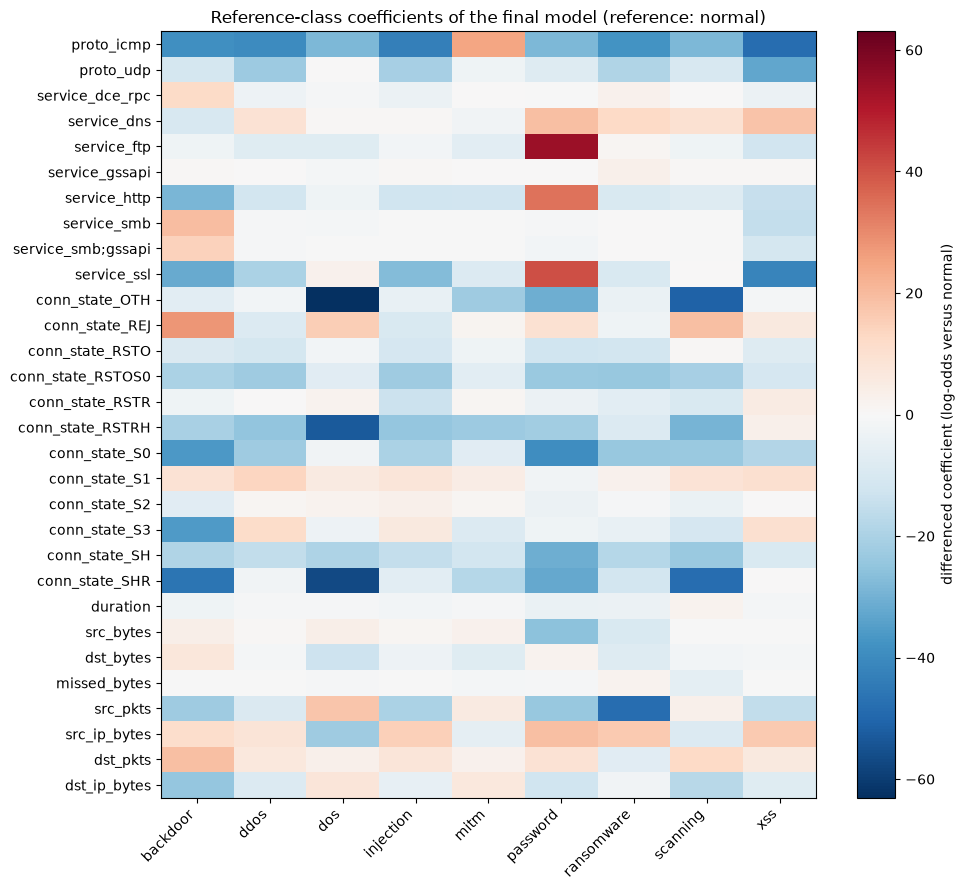

In [32]:
# Remove the reference column: it is all zeros and adds nothing to the figure
plot_table = coef_diff.drop(columns=REFERENCE_NAME)

# Symmetric colour limits, so that 0 is always the white centre of the colour map
limit = np.abs(plot_table.to_numpy()).max()

fig, ax = plt.subplots(figsize=(10,9))
# Red = positive coefficient, blue = negative, white = close to zero
image = ax.imshow(plot_table.to_numpy(), cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")

# Class names on the x axis, predictor names on the y axis
ax.set_xticks(range(len(plot_table.columns)))
ax.set_xticklabels(plot_table.columns, rotation=45, ha="right")
ax.set_yticks(range(len(plot_table.index)))
ax.set_yticklabels(plot_table.index)

fig.colorbar(image, ax=ax, label="differenced coefficient (log-odds versus " + REFERENCE_NAME + ")")
ax.set_title("Reference-class coefficients of the final model (reference: " + REFERENCE_NAME + ")")
fig.tight_layout()
plt.show()

**Interpretation of the figure.** 

Each cell is a differenced coefficient $w_c$: the change in log-odds of the class in the column versus `normal` when the predictor in the row goes up by one unit (one dummy switched on, or one standard deviation of `log1p` for a numeric column). The colour scale goes to ±60.2, set by `conn_state_OTH` for `dos`.

1. **The categorical dummies carry the strongest effects.** `proto_icmp` is strongly negative for every attack except `mitm` (+24.1), so ICMP traffic points to either `normal` or `mitm`. `service_ftp`, `service_ssl` and `service_http` are strongly positive only for `password` (+53.4, +40.6, +34.3), and `service_smb`, `service_smb;gssapi` and `service_dce_rpc` mainly for `backdoor` (+18.4, +14.0, +12.7). `conn_state_REJ` is positive for `backdoor` (+26.4), `scanning` (+19.9) and `dos` (+15.9), which matches rejected connection attempts. Most other `conn_state` rows (`OTH`, `RSTOS0`, `RSTRH`, `S0`, `SH`, `SHR`) are blue for almost every class, so, compared with `SF`, these states push the prediction towards `normal`.
2. **The numeric packet and byte counts come in pairs with opposite signs.** For `backdoor`, `src_pkts` is −23.1 against `src_ip_bytes` +12.2, and `dst_pkts` +18.7 against `dst_ip_bytes` −24.1. These pairs are strongly correlated (IP bytes grow with the number of packets), so the model offsets one with the other. Their signs should not be read one by one; only their combination is meaningful.
3. **Many coefficients are above 20 in absolute value**, which means odds ratios above $e^{20} \approx 5 \times 10^8$. This is the expected sign of an unpenalised model on almost separable classes. The figure shows which predictors and directions matter, but not reliable effect sizes.

# P3.5 — Challenge A against Practice 2

## Paired comparison against Practice 2

**The Practice 3 row of Challenge A.** Every value is copied from the saved outputs of R2's
notebook (P3.1). The spread is computed from the printed fold values, as in the Practice 2
rows. Before the row is added, the cell checks that the copied mean and spread agree with
the five copied fold values, to catch a typing mistake.

In [33]:
# Practice 3 row of Challenge A, copied from the saved outputs of R2's notebook
cyber_row = {
    "milestone": "P3",
    "challenge": "cyber",
    "family": "LogisticRegression",
    "route": "primary",
    "configuration": "multinomial, C=np.inf (no penalty; get_params() printed), "
                     "class_weight=None, solver=lbfgs, max_iter=5000; no hyperparameter search",
    "preprocessing": "one-hot on 3 nominal predictors with one reference level dropped "
                     "(proto=tcp, service=-, conn_state=SF), unseen level encoded as the "
                     "reference; log1p then StandardScaler on 8 numeric predictors; "
                     "fitted inside each fold",
    "features": "features.md: the 11 distributed source predictors (frozen basis)",
    "validation": "canonical StratifiedGroupKFold(5) on feature_group, "
                  "read from folds/cyber_folds.csv",
    "primary_metric_per_fold": "0.8407 0.8332 0.8453 0.8353 0.8361",
    "primary_metric": 0.8381,
    "primary_metric_spread": 0.0121,
    "supporting_metrics": "weighted F1 0.8533; accuracy 0.8546; per-class "
                          "precision/recall/F1/support and confusion in p3_cyber.ipynb",
    "fit_time_s": 7.6659,
    "interpretability": "odds ratios exp(beta_c - beta_r) of each class against the "
                        "reference class normal (P3.2)",
    "notes": "unpenalised linear model on the log-odds; mitm is the weakest class; coef_ has "
             "29 columns in fold 3 because service=gssapi is absent from its training rows",
}

# Check against typing mistakes: mean and spread must agree with the five fold values
copied_folds = np.array(cyber_row["primary_metric_per_fold"].split(), dtype=float)
mean_check, spread_check = mean_and_spread(copied_folds)
assert abs(mean_check - cyber_row["primary_metric"]) < 0.0001
assert abs(spread_check - cyber_row["primary_metric_spread"]) < 0.00001

# Add the row at the end of comparativa.csv (the Practice 2 rows are not touched)
append_comparativa_row(cyber_row)

added to comparativa.csv: P3 cyber LogisticRegression


In [34]:
# Paired differences, both rows read from comparativa.csv
new_scores = table_scores("P3", "cyber", "LogisticRegression")
old_scores = table_scores("P2", "cyber", "KNN")

# delta = P3 - P2 for macro F1, so a positive value means the logistic regression did better
cyber_deltas = paired_differences("cyber", new_scores, old_scores)

          P2     new   delta
fold                        
1     0.9436  0.8407 -0.1029
2     0.9473  0.8332 -0.1141
3     0.9490  0.8453 -0.1037
4     0.9428  0.8353 -0.1075
5     0.9451  0.8361 -0.1090
mean delta            -0.1074
spread of delta       0.0112   (max - min)
folds with delta > 0  0 of 5
spread of P2 row      0.0062
spread of new row     0.0121


**Reading of the differences, and which kind of comparison this is.** The logistic
regression has a lower macro F1 than the Practice 2 KNN on all five folds. The mean
difference is −0.1074, and the five differences stay within 0.0112 of each other, so the
drop has about the same size on every fold. It is also much larger than the fold-to-fold
spread of either row (0.0062 for KNN, 0.0121 for the logistic regression). This describes
these five folds, it is not a statistical test.

The two rows do not use the same representation: Practice 2 one-hot encodes every level of
the nominal predictors, while Practice 3 drops one reference level per predictor. So this is
a **pipeline comparison**, not an isolated comparison of model families: it says that this
pipeline did worse than that one on these folds, not that the model family alone explains
the difference.

In [35]:
# Macro F1 of the Practice 2 model on the same five canonical folds
P2_MACRO_F1 = [0.9436, 0.9473, 0.9490, 0.9428, 0.9451]

# Check: the mean must match the value stored in comparativa.csv
assert round(np.mean(P2_MACRO_F1), 4) == 0.9456

# One row per fold: both models side by side
paired = pd.DataFrame({
    "practice_2": P2_MACRO_F1,
    "logreg": lr_macro.to_numpy(),
}, index=lr_macro.index)

# Paired difference: positive means logistic regression did better in that fold
paired["difference"] = paired["logreg"] - paired["practice_2"]
display(paired.round(4))

# Descriptive summary of the five differences
print("mean difference:", round(paired["difference"].mean(), 4))
print("smallest difference:", round(paired["difference"].min(), 4))
print("largest difference:", round(paired["difference"].max(), 4))
print("folds where logistic regression is better:", (paired["difference"] > 0).sum(), "of 5")

# Macro F1 of the Dummy baseline in Practice 2
DUMMY_MACRO_F1 = 0.0242
# Gap between the Dummy and a perfect score of 1
gap = 1 - DUMMY_MACRO_F1
# Share of that gap closed by each model, in percent
print("KNN closes:", round((np.mean(P2_MACRO_F1) - DUMMY_MACRO_F1)/gap*100, 1), "% of the gap")
print("logistic regression closes:", round((lr_macro.mean() - DUMMY_MACRO_F1) / gap*100, 1), "% of the gap")

,practice_2,logreg,difference
fold,,,
0,0.9436,0.8406,-0.1030
1,0.9473,0.8333,-0.1140
2,0.9490,0.8455,-0.1035
3,0.9428,0.8338,-0.1090
4,0.9451,0.8355,-0.1096


mean difference: -0.1078
smallest difference: -0.114
largest difference: -0.103
folds where logistic regression is better: 0 of 5
KNN closes: 94.4 % of the gap
logistic regression closes: 83.4 % of the gap


### The six fixed comparison questions

1. **Size and consistency of the change.** Using the five paired differences (descriptive only). The logistic regression is worse than Practice 2's KNN in **all five folds**: the paired differences in macro F1 go from −0.1141 to −0.1029, with a mean of **−0.1074**. The five differences lie within 0.0112 of each other. That is about ten times smaller than their size, and similar to the fold-to-fold range of the logistic regression itself (0.0121). The drop is therefore large and consistent. This is a descriptive comparison of five paired values, not a statistical test. The logistic regression is also about twice as variable across folds as KNN (macro F1 range 0.0121 against 0.0062, both from the printed per-fold scores).
2. **Route and representation.** Pipeline comparison or isolated family comparison, and what the evidence licenses. Both models use the primary route, the same 11 frozen predictors, the same five canonical folds and almost the same preprocessing, fitted inside each fold (one-hot on the nominal predictors, `log1p` + `StandardScaler` on the numeric ones). The only change in the representation is that the logistic regression drops one reference level per nominal predictor. Strictly this is a pipeline comparison, but a very close one to an isolated family comparison. One asymmetry remains: KNN's `k` was chosen on the same folds it is scored on, so its 0.9456 is slightly optimistic. That optimism is far too small to explain a gap of 0.107. The evidence supports the claim that this unpenalised linear model is clearly worse than this KNN on these folds and this representation, not a general claim about the two families.
3. **What can the new family express** that the previous one could not? Logistic regression gives an explicit probability model and one global coefficient per predictor and class, so each effect can be read as an odds ratio versus `normal`, and the probabilities can be checked by hand (P3.2). KNN only votes among nearby points and has no such summary. In return, logistic regression can only draw boundaries that are linear in the transformed predictors, while KNN can follow non-linear ones. The confusion matrix shows where this matters: `xss` versus `ddos` and `injection`, and `dos` versus `normal` and `scanning`, are classes that overlap and need boundaries that a linear model cannot draw in this representation.
4. **What did it cost** in fitting time, tuning effort and interpretability? *Fitting time:* about 8.0 s per fold, against about 0.035 s for KNN, which only stores the data. *Tuning effort:* none, against 9 values of `k` for KNN. *Interpretability:* higher in principle, but limited in practice: without a penalty the coefficients reach ±60, correlated pairs such as `src_pkts` and `src_ip_bytes` take opposite signs, and the number of columns changes in fold 3 because of the single `gssapi` row.
5. **Did the ordering of the two challenges' difficulty change**, and why? The two challenges use different metrics, so we compare each model with its own Dummy using the same rule in both: the share of the gap between the Dummy and a perfect score that the model closes (for MAE a perfect score is 0, so this is the relative reduction in MAE). In cyber, KNN closes 94 % of the gap from the Dummy macro F1 (0.0242) to 1, and logistic regression 83 % (macro F1 0.8381 against 0.9456, worse in all five folds). In storage, KNN cuts the Dummy's MAE(z) of 0.677 by 73 % (0.180), and LinearRegression by 71 % (0.1981). The ordering did not change: storage remains the harder challenge with both families. But the linear model lost much more in cyber (about 11 percentage points against about 3). Our untested explanation: some cyber classes overlap in ways that a linear boundary cannot separate, as the `xss`–`ddos` and `dos`–`normal` confusions show, while z is close to additive in the predictors. **Why the ordering came out this way** KNN beats the unpenalised logistic regression in all five folds (by 0.107 on average), most likely because a linear boundary cannot separate classes that overlap.
6. **Would you ship the new model?** If not, what would change your mind? No, not as the main detector. It loses about 0.107 macro F1 in every fold, and it misses more than half of the `mitm` connections (recall 0.458). It is useful as an interpretable reference, to explain which services and connection states are associated with each attack. What would change our mind: a penalised logistic regression, with `C` tuned on the same folds and with interaction terms (for example `service` × `conn_state`), that closes the gap to KNN to within the fold-to-fold range (about 0.01) while keeping coefficients of a readable size.

# Comparison table

The Practice 3 rows are added in the paired-comparison part of each challenge, just before
their differences are computed, because the differences are read from the table. This last
cell shows the whole table so that we can check that the four Practice 2 rows are still the
first rows, unchanged, and that the new rows come after them.

Practice 2 and Practice 3 do not use the same representation of the nominal predictors:
Practice 2 one-hot encodes every level, Practice 3 drops one reference level per predictor.
The information basis is the same (the same source predictors, no derived feature), but the
representation is not, so every Practice 3 against Practice 2 difference is a **pipeline
comparison**, not an isolated comparison of model families.

In [36]:
# Read the whole table and show its main columns
table = pd.read_csv(COMPARISON_PATH)
print(table[["milestone", "challenge", "family", "route",
             "primary_metric", "primary_metric_spread"]].to_string())

# The table is only appended to: the Practice 2 rows are still the first four rows
assert list(table["milestone"].iloc[:4]) == ["P2", "P2", "P2", "P2"]

  milestone challenge              family    route  primary_metric  primary_metric_spread
0        P2     cyber               Dummy  primary          0.0242                 0.0000
1        P2   storage               Dummy  primary          0.6770                 0.0294
2        P2     cyber                 KNN  primary          0.9456                 0.0062
3        P2   storage                 KNN  primary          0.1800                 0.0109
4        P3   storage    LinearRegression  primary          0.1981                 0.0110
5        P3     cyber  LogisticRegression  primary          0.8381                 0.0121
